# Food Delivery Time Prediction: EDA and model comparison
**Goal:** predict delivery time (minutes) from order, courier, traffic and weather information.
**Data:** Kaggle *Food Delivery Dataset* (`train.csv`, ~45k orders from Indian cities). Target: `Time_taken(min)`.
**Run:** from the repo root, `jupyter notebook notebooks/notebook.ipynb`. In Colab, run the first cell to clone the repo.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('train.py'):
    !git clone https://github.com/Suyog-Shrestha/Food-Delivery-time-prediction.git repo
    %cd repo
    !pip install -q -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from train import load_and_clean, build_features, evaluate, FEATURES, SEED
sns.set_theme(style='whitegrid')

## 1. Load and look at the raw data

In [3]:
raw = pd.read_csv('data/train.csv'); raw.columns = [c.strip() for c in raw.columns]
print(raw.shape); raw.head()

(45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [4]:
raw = raw.replace(r'^\s*NaN\s*$', np.nan, regex=True)
print(raw.isna().sum()[lambda s: s > 0])

Delivery_person_Age        1854
Delivery_person_Ratings    1908
Time_Orderd                1731
Road_traffic_density        601
multiple_deliveries         993
Festival                    228
City                       1200
dtype: int64


Notes from inspection: numeric columns arrive as text, categories have trailing spaces, the target looks like `(min) 24`, missing values are the string `NaN`, and some rows have negative or zero GPS coordinates. `load_and_clean` in `train.py` handles all of this.

## 2. Cleaning and feature engineering
Features built: `cook_diff` (minutes from order to pickup, midnight wrap fixed), `order_hour`, `distance` (Euclidean distance in degrees between restaurant and drop-off, using absolute coordinates) and one-hot encoded categories.

In [5]:
df = load_and_clean('data/train.csv')
print(f'{len(raw)} raw rows -> {len(df)} after dropping rows with missing values')
df.head(3)

45593 raw rows -> 42453 after dropping rows with missing values


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),target,cook_diff,order_hour,distance
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,...,Snack,motorcycle,0.0,No,Urban,(min) 24,24.0,15.0,11.0,0.028284
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,...,Snack,scooter,1.0,No,Metropolitian,(min) 33,33.0,5.0,19.0,0.183848
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,...,Drinks,motorcycle,1.0,No,Urban,(min) 26,26.0,15.0,8.0,0.014142


## 3. EDA

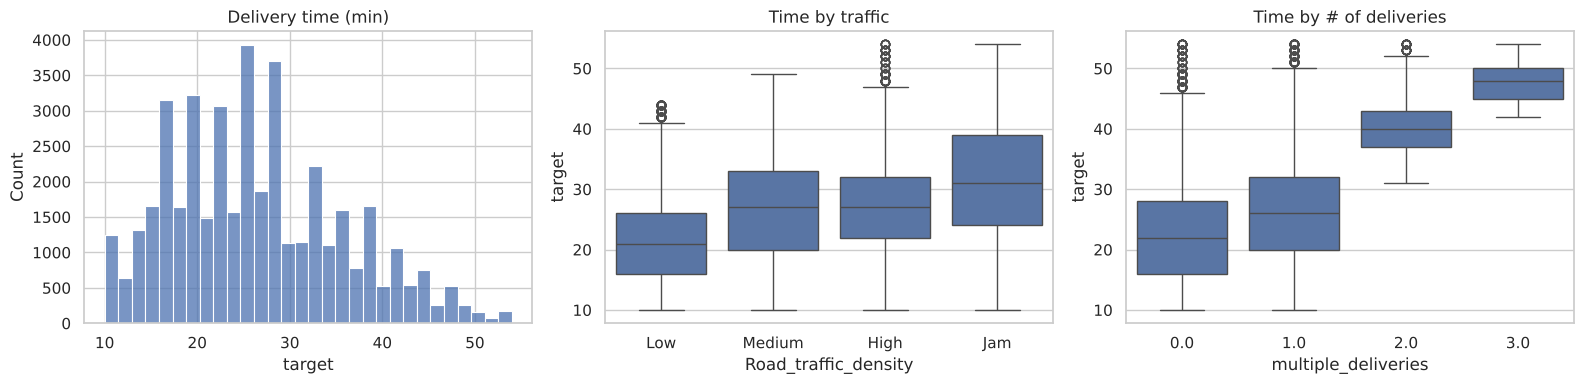

count    42453.000000
mean        26.444303
std          9.333968
min         10.000000
25%         19.000000
50%         26.000000
75%         33.000000
max         54.000000
Name: target, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['target'], bins=30, ax=ax[0]); ax[0].set_title('Delivery time (min)')
sns.boxplot(data=df, x='Road_traffic_density', y='target', order=['Low','Medium','High','Jam'], ax=ax[1]); ax[1].set_title('Time by traffic')
sns.boxplot(data=df, x='multiple_deliveries', y='target', ax=ax[2]); ax[2].set_title('Time by # of deliveries')
plt.tight_layout(); plt.show()
print(df['target'].describe())

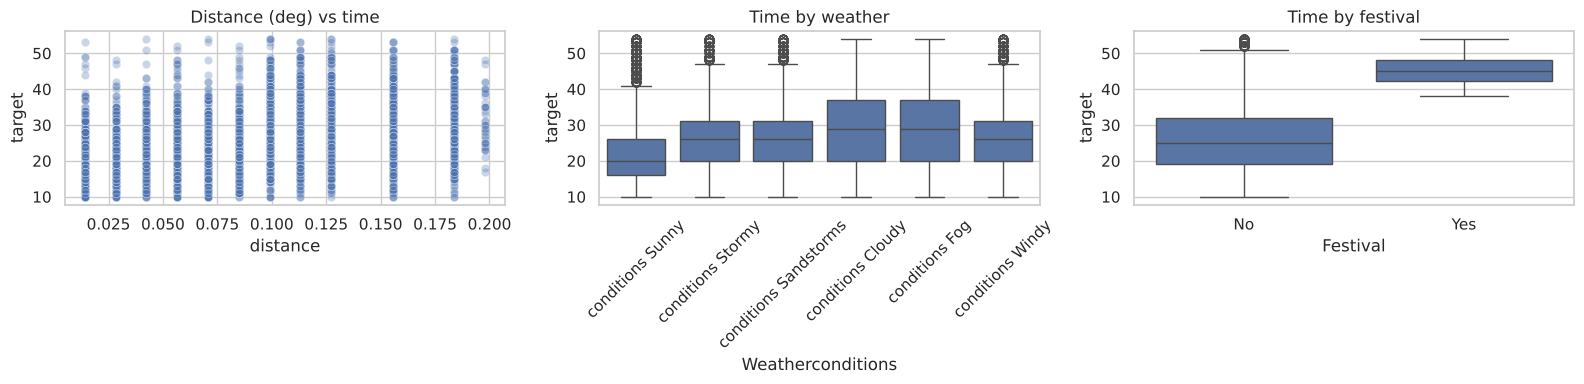

distance quantiles: {0.5: 0.085, 0.95: 0.184, 0.99: 0.198, 1.0: 0.198}


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df.sample(4000, random_state=SEED), x='distance', y='target', alpha=.3, ax=ax[0]); ax[0].set_title('Distance (deg) vs time')
sns.boxplot(data=df, x='Weatherconditions', y='target', ax=ax[1]); ax[1].tick_params(axis='x', rotation=45); ax[1].set_title('Time by weather')
sns.boxplot(data=df, x='Festival', y='target', ax=ax[2]); ax[2].set_title('Time by festival')
plt.tight_layout(); plt.show()
print('distance quantiles:', df['distance'].quantile([.5,.95,.99,1]).round(3).to_dict())

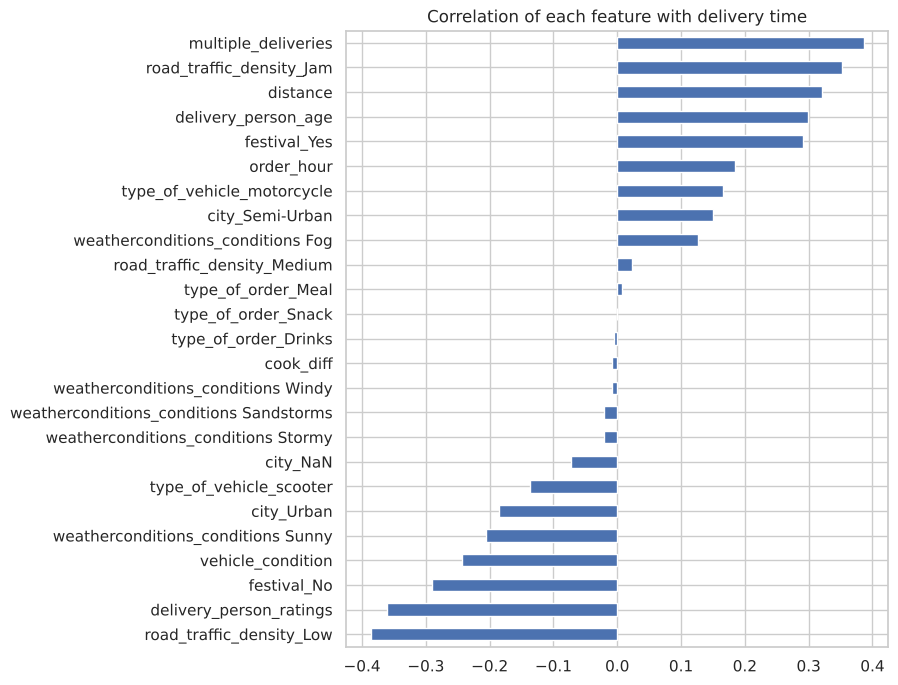

In [8]:
X, y = build_features(df), df['target']
corr = pd.concat([X, y], axis=1).corr()['target'].drop('target').sort_values()
corr.plot.barh(figsize=(7, 8), title='Correlation of each feature with delivery time'); plt.show()

**Takeaways:** traffic jams, multiple concurrent deliveries and festivals raise delivery time; higher courier ratings and low traffic lower it. A few rows have very large distance values (bad GPS data), which tree models tolerate but linear regression does not.

## 4. Train / test split and model comparison
Same 80/20 split for every model (`random_state=42`).

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    'XGBoost (default)': xgb.XGBRegressor(random_state=SEED),
}
rows = []
for name, m in models.items():
    m.fit(X_tr, y_tr); rows.append({'model': name, **evaluate(y_te, m.predict(X_te))})
pd.DataFrame(rows).round(3)

,model,RMSE,MAE,R2
0,Linear Regression,5.906,4.697,0.597
1,Random Forest,3.822,3.053,0.831
2,XGBoost (default),3.815,3.047,0.832


## 5. Tune the best model (XGBoost)

In [10]:
param_grid = {'n_estimators': [200, 300, 500], 'learning_rate': [0.03, 0.05, 0.1],
              'max_depth': [4, 6, 8], 'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.7, 0.8, 1.0],
              'min_child_weight': [1, 3, 5]}
search = RandomizedSearchCV(xgb.XGBRegressor(random_state=SEED), param_grid, n_iter=15, cv=3,
                            scoring='neg_root_mean_squared_error', random_state=SEED, n_jobs=-1)
search.fit(X_tr, y_tr)
print('best params:', search.best_params_)
print('CV RMSE:', round(-search.best_score_, 3))

best params: {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
CV RMSE: 3.762


In [11]:
best = search.best_estimator_
rows.append({'model': 'XGBoost (tuned)', **evaluate(y_te, best.predict(X_te))})
results = pd.DataFrame(rows).round(3); results

,model,RMSE,MAE,R2
0,Linear Regression,5.906,4.697,0.597
1,Random Forest,3.822,3.053,0.831
2,XGBoost (default),3.815,3.047,0.832
3,XGBoost (tuned),3.771,3.024,0.836


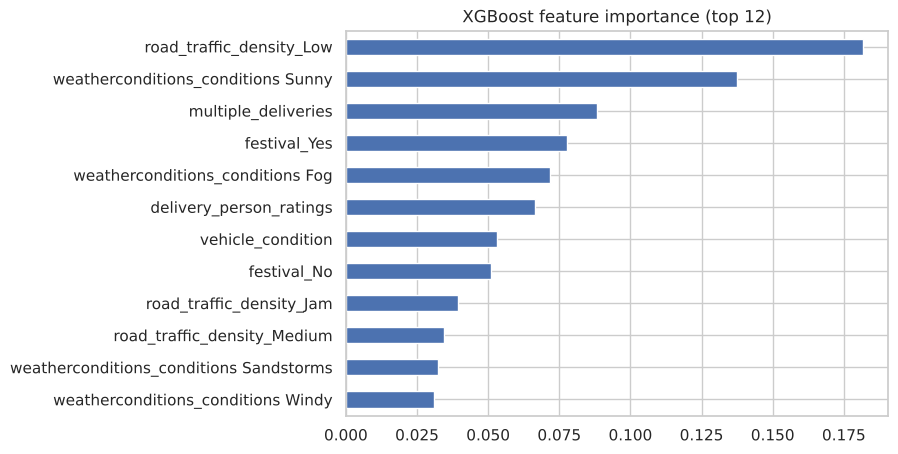

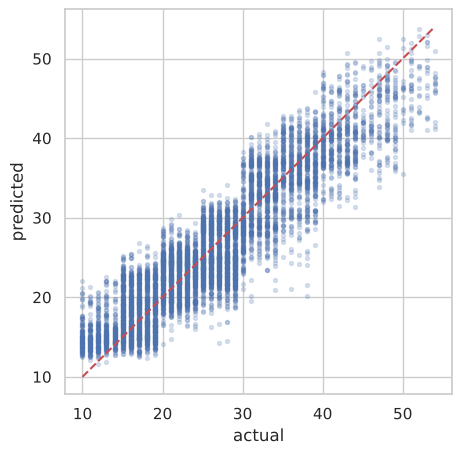

In [12]:
fi = pd.Series(best.feature_importances_, index=FEATURES).sort_values()
fi.tail(12).plot.barh(title='XGBoost feature importance (top 12)', figsize=(7, 5)); plt.show()
plt.figure(figsize=(5, 5)); plt.scatter(y_te, best.predict(X_te), alpha=.2, s=8)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--'); plt.xlabel('actual'); plt.ylabel('predicted'); plt.show()

## 6. Conclusion
Gradient-boosted trees clearly beat linear regression because delivery time depends on interactions (traffic x distance x multiple deliveries). Tuned XGBoost is the final model, saved by `train.py` to `models/food_delivery_time_model.json` and served by `predict.py` (FastAPI) and `app.py` (Streamlit).

**Limitations:** `cook_diff` (order-to-pickup time) is only known once the restaurant hands over the food, so predictions are best made at pickup; the data comes from one dataset and period; some GPS coordinates were noisy.